# CV-Job Matching — EDA + Eksperimen (semua task dalam satu notebook)
**Cukup klik *Run All*.** Urutan: EDA Task 1–3, lalu Eksperimen Task 1–3. Chart tersimpan ke `../figures/`, tabel hasil ke `../data/`.

- Tiap bagian memakai namespace bersih (`%reset -f`) sehingga variabel antar-task tidak bentrok.
- Eksperimen Task 1 (fine-tune BERT) lambat di CPU. Set `RUN_BERT="0"` di cell konfigurasi di bawah untuk melewatinya (Colab GPU: biarkan "1").
- Catatan dataset: lihat markdown di tiap bagian (job-desc tanpa label NER, Field = mapping manual, dll.).
- Versi terpisah per-task tetap ada di folder ini.

In [6]:
# Requirements — dijalankan sekali untuk seluruh notebook
%pip install -q kagglehub datasets pyarrow pandas numpy scipy scikit-learn sklearn-crfsuite nltk transformers torch matplotlib seaborn wordcloud

Note: you may need to restart the kernel to use updated packages.


In [7]:
import os
os.environ["RUN_BERT"] = "1"   # "0" = lewati fine-tuning BERT di eksperimen Task 1

---
# BAGIAN: Task 1 — EDA NER

In [8]:
%reset -f
import gc; gc.collect()

0

# EDA Task 1 — NER (Resume NER + Job Descriptions)
Menghasilkan chart ke `../figures/`.

**Catatan penting:** file `khaliladimassi/cleaned-job-description` berisi `job_title, company_name, job_description, clean_text` (+ tabel O*NET) — **tidak ada anotasi NER**. Lihat temuan di bawah (baris pertama file berbahasa Swedia, tapi sample acak ~98% Inggris).

In [9]:
import os, re, json, glob, warnings, collections
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
SEED = 42; np.random.seed(SEED)
FIG, DATA = "../figures", "../data"
os.makedirs(FIG, exist_ok=True); os.makedirs(DATA, exist_ok=True)
os.environ["KAGGLEHUB_CACHE"] = os.path.abspath(f"{DATA}/kaggle")
sns.set_theme(style="whitegrid")
def save(name):
    plt.tight_layout(); plt.savefig(f"{FIG}/{name}.png", dpi=150, bbox_inches="tight"); plt.show()

In [10]:
import kagglehub
p = kagglehub.dataset_download("yashpwrr/resume-ner-training-dataset")
cv = json.load(open(glob.glob(f"{p}/**/train.json", recursive=True)[0], encoding="utf8"))
SURR = re.compile("[" + chr(0xd800) + "-" + chr(0xdfff) + "]")  # lone surrogate di sebagian teks -> ganti 1:1 (offset anotasi tetap valid)
n_bad = sum(bool(SURR.search(x["text"])) for x in cv)
for x in cv: x["text"] = SURR.sub(chr(0xfffd), x["text"])
print(len(cv), "CV |", n_bad, "CV mengandung karakter surrogate rusak (dibersihkan)")

5960 CV | 1 CV mengandung karakter surrogate rusak (dibersihkan)


## 1. Ukuran & struktur (CV)

In [11]:
rows = [(i, a[0], a[1], a[2], x["text"][a[0]:a[1]]) for i, x in enumerate(cv) for a in x["annotations"]]
ann = pd.DataFrame(rows, columns=["doc","start","end","label","span"])
docs = pd.DataFrame({"text":[x["text"] for x in cv]})
docs["n_chars"] = docs.text.str.len(); docs["n_tok"] = docs.text.str.split().str.len()
docs["n_ann"] = ann.groupby("doc").size().reindex(range(len(cv))).fillna(0).values
print("docs:", len(docs), "| anotasi:", len(ann), "| kolom: text, annotations (list [start,end,label])")
print("missing text:", (docs.text.str.strip()=="").sum(), "| docs tanpa anotasi:", (docs.n_ann==0).sum())
display(docs.describe().T)

docs: 5960 | anotasi: 579575 | kolom: text, annotations (list [start,end,label])
missing text: 0 | docs tanpa anotasi: 0


,count,mean,std,min,25%,50%,75%,max
n_chars,5960.0,4447.507718,4249.990256,19.0,2224.75,3537.0,5616.75,99973.0
n_tok,5960.0,579.322651,593.239237,4.0,270.00,447.0,735.00,15081.0
n_ann,5960.0,97.244128,68.258607,1.0,48.00,82.0,134.00,591.0


## 2. Distribusi entity type

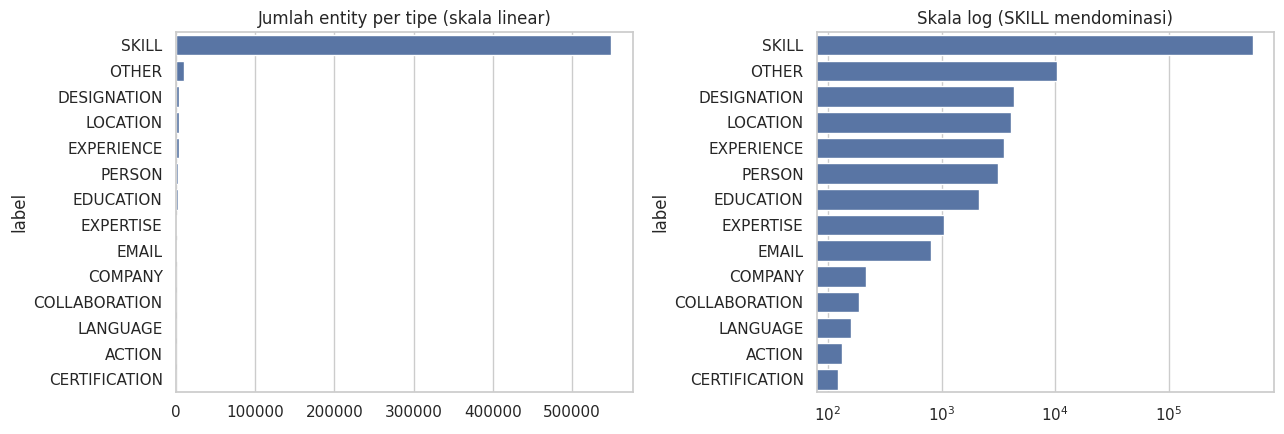

label
SKILL            549465
OTHER             10267
DESIGNATION        4301
LOCATION           4073
EXPERIENCE         3544
PERSON             3122
EDUCATION          2124
EXPERTISE          1045
EMAIL               815
COMPANY             218
COLLABORATION       187
LANGUAGE            159
ACTION              133
CERTIFICATION       122


In [12]:
vc = ann.label.value_counts()
fig, ax = plt.subplots(1, 2, figsize=(13,4.5))
sns.barplot(x=vc.values, y=vc.index, ax=ax[0], color="#4C72B0"); ax[0].set_title("Jumlah entity per tipe (skala linear)")
sns.barplot(x=vc.values, y=vc.index, ax=ax[1], color="#4C72B0"); ax[1].set_xscale("log"); ax[1].set_title("Skala log (SKILL mendominasi)")
save("t1_entity_distribution"); print(vc.to_string())

## 3. Panjang teks

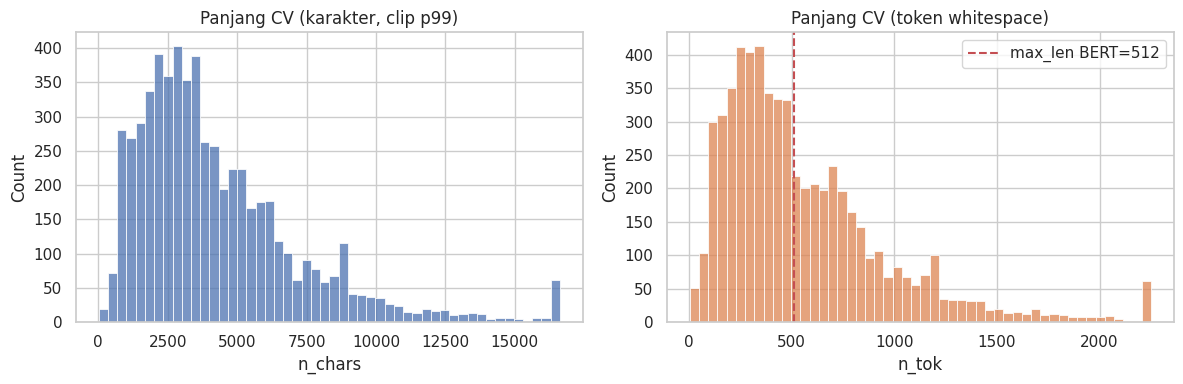

persen CV > 512 token whitespace: 42.3 % -> perlu chunking/sliding window


In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12,4))
sns.histplot(docs.n_chars.clip(upper=docs.n_chars.quantile(.99)), bins=50, ax=ax[0]); ax[0].set_title("Panjang CV (karakter, clip p99)")
sns.histplot(docs.n_tok.clip(upper=docs.n_tok.quantile(.99)), bins=50, ax=ax[1], color="C1"); ax[1].set_title("Panjang CV (token whitespace)")
ax[1].axvline(512, color="r", ls="--", label="max_len BERT=512"); ax[1].legend()
save("t1_cv_length")
print("persen CV > 512 token whitespace:", round((docs.n_tok>512).mean()*100,1), "% -> perlu chunking/sliding window")

## 4. Skill paling sering

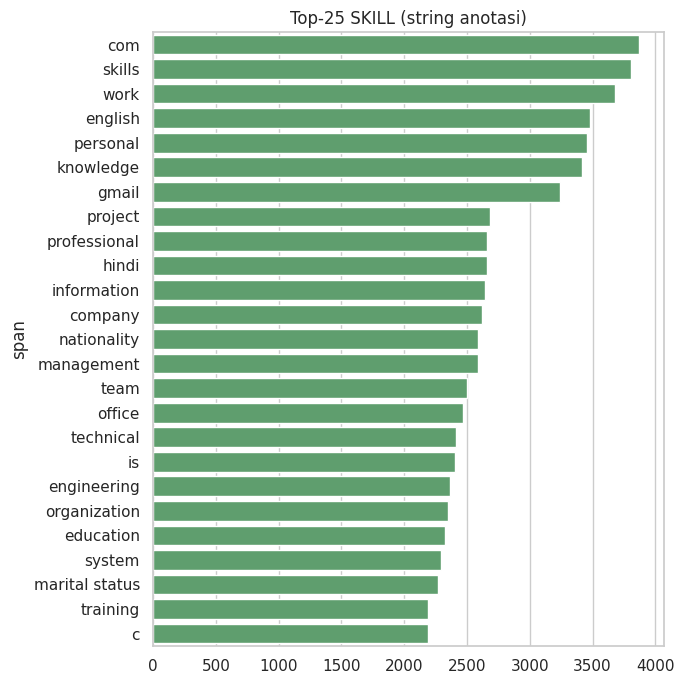

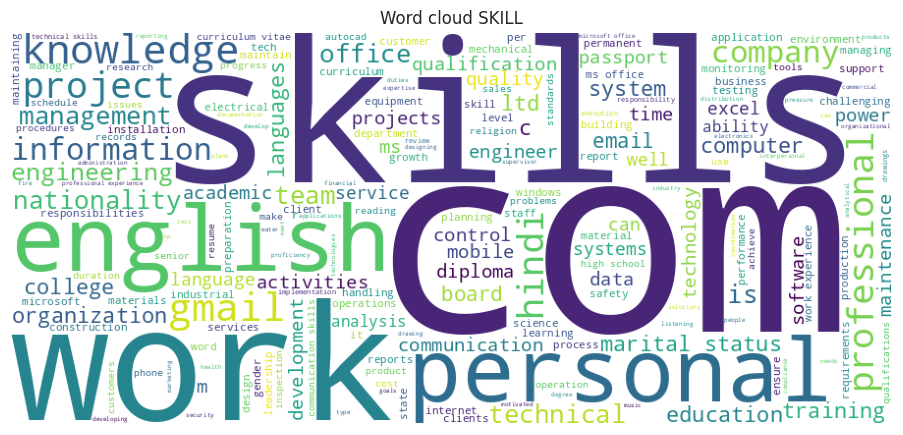

In [14]:
top = ann[ann.label=="SKILL"].span.str.lower().str.strip().value_counts().head(25)
plt.figure(figsize=(7,7)); sns.barplot(x=top.values, y=top.index, color="#55A868"); plt.title("Top-25 SKILL (string anotasi)")
save("t1_top_skills")
from wordcloud import WordCloud
short = ann[(ann.label=="SKILL") & (ann.span.str.len()<40)].span.str.lower()
wc = WordCloud(width=900, height=400, background_color="white").generate_from_frequencies(short.value_counts().to_dict())
plt.figure(figsize=(10,4.5)); plt.imshow(wc); plt.axis("off"); plt.title("Word cloud SKILL"); save("t1_skill_wordcloud")

## 5. Duplikasi / keunikan

In [15]:
print("teks CV unik:", docs.text.nunique(), "/", len(docs), f"({docs.text.nunique()/len(docs):.1%})")
print("prefix 300 karakter unik:", docs.text.str[:300].nunique(), "(deteksi near-duplicate)")
print("span SKILL unik:", ann[ann.label=='SKILL'].span.str.lower().nunique(), "/", (ann.label=='SKILL').sum())

teks CV unik: 4290 / 5960 (72.0%)
prefix 300 karakter unik: 4234 (deteksi near-duplicate)
span SKILL unik: 18225 / 549465


## 6. Kualitas anotasi

,jumlah
out_of_bounds,0
whitespace_di_tepi_span,3008
span_overlap,67786
span_>100_char,454
string_dgn_label_ganda,1290


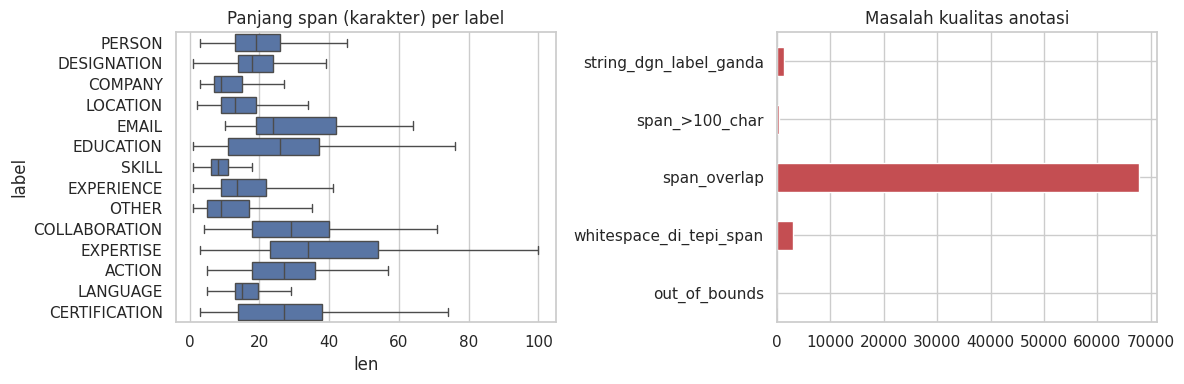

contoh string berlabel ganda: ['.net', '10 years', '10 years experience', '10 years of experience', '10+ years of experience', '12 months', '12 years experience', '12 years of experience', '13 years of experience', '15 years experience']
catatan: label OTHER = 10267 anotasi; tentukan apakah di-drop saat training.


In [16]:
ann["len"] = ann.end - ann.start
ann["oob"] = (ann.end <= ann.start) | (ann.start < 0) | (ann.end > ann.doc.map(docs.n_chars))
ann["ws_edge"] = ann.span.ne(ann.span.str.strip())
ann = ann.sort_values(["doc","start"]); prev_end = ann.groupby("doc").end.shift()
ann["overlap"] = prev_end.notna() & (ann.start < prev_end)
# string yang sama diberi >1 label (tidak konsisten)
g = ann.assign(k=ann.span.str.lower().str.strip()).groupby("k").label.nunique()
conf = g[g>1]
q = pd.DataFrame({"out_of_bounds":[ann.oob.sum()], "whitespace_di_tepi_span":[ann.ws_edge.sum()], "span_overlap":[ann.overlap.sum()],
                  "span_>100_char":[(ann.len>100).sum()], "string_dgn_label_ganda":[len(conf)]}).T.rename(columns={0:"jumlah"})
display(q)
fig, ax = plt.subplots(1,2, figsize=(12,4))
sns.boxplot(data=ann[ann.len<400], x="len", y="label", ax=ax[0], showfliers=False); ax[0].set_title("Panjang span (karakter) per label")
q["jumlah"].plot.barh(ax=ax[1], color="C3"); ax[1].set_title("Masalah kualitas anotasi")
save("t1_annotation_quality")
print("contoh string berlabel ganda:", list(conf.index[:10]))
print("catatan: label OTHER =", (ann.label=='OTHER').sum(), "anotasi; tentukan apakah di-drop saat training.")

## 7. Job descriptions (sample)

In [17]:
import kagglehub, pyarrow.parquet as pq
pj = kagglehub.dataset_download("khaliladimassi/cleaned-job-description")
JOB_N = 20000  # ukuran sample job posting (dari 159.589 baris file asli)
job = pq.read_table(glob.glob(f"{pj}/**/cleaned_jobs_desc.parquet", recursive=True)[0], columns=["job_title","company_name","job_description"]).to_pandas()
print("total baris job file:", len(job))
job = job.sample(JOB_N, random_state=SEED).reset_index(drop=True)
print("sample dipakai:", len(job))

Mounting files to /kaggle/input/datasets/khaliladimassi/cleaned-job-description...


KeyboardInterrupt: 

In [ ]:
d = job.job_description.fillna("")
job["n_tok"] = d.str.split().str.len()
print("missing description:", job.job_description.isna().sum(), "| kolom:", list(job.columns), "| TIDAK ada kolom anotasi NER")
EN = set("the and of to in for with a is are you our we will your experience team work".split())
SV = set("och att som för med är vi du har till av en ett på de det om".split())
def lang(t):
    w = re.findall(r"\w+", str(t).lower())[:200]
    e, s = sum(x in EN for x in w), sum(x in SV for x in w); return "en" if e>s else ("sv" if s>e else "?")
job["lang"] = d.map(lang)
print(job.lang.value_counts(normalize=True).round(3).to_dict())
print("teks unik:", d.nunique(), "/", len(job), "| judul unik:", job.job_title.nunique())
fig, ax = plt.subplots(1,3, figsize=(15,4))
sns.histplot(job.n_tok.clip(upper=job.n_tok.quantile(.99)), bins=50, ax=ax[0]); ax[0].set_title("Panjang job desc (token)")
job.lang.value_counts().plot.bar(ax=ax[1], color="C2"); ax[1].set_title("Bahasa (heuristik stopword)")
tw = collections.Counter(w for t in d.head(3000) for w in re.findall(r"[a-zA-ZåäöÅÄÖ]{4,}", t.lower())).most_common(20)
ax[2].barh([w for w,_ in tw][::-1], [c for _,c in tw][::-1]); ax[2].set_title("Top kata (3000 posting)")
save("t1_job_desc_overview")
print("-> Cek proporsi non-en: posting non-Inggris perlu difilter sebelum NER berbahasa Inggris dipakai.")

---
# BAGIAN: Task 2 — EDA Classification

In [18]:
%reset -f
import gc; gc.collect()

0

# EDA Task 2 — Classification (ResumeAtlas)
Output: **Field**, **Sub-field**, **Level Seniority**.

Dataset: `ahmedheakl/resume-atlas` (13.389 CV, 43 kategori; kolom `Category`, `Text`; hanya split `train`). *Sub-field* = `Category` langsung; *Field* = mapping manual `FIELD_MAP` (asumsi, 7 Bidang); *Level* = heuristik years-of-experience (<2 Entry, 2–5 Mid, >5 Senior) dari regex pada teks CV (pengganti output NER). Teks sumber sudah lowercase tanpa tanda baca.

In [19]:
import os, re, json, glob, warnings, collections
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
SEED = 42; np.random.seed(SEED)
FIG, DATA = "../figures", "../data"
os.makedirs(FIG, exist_ok=True); os.makedirs(DATA, exist_ok=True)
os.environ["KAGGLEHUB_CACHE"] = os.path.abspath(f"{DATA}/kaggle")
sns.set_theme(style="whitegrid")
def save(name):
    plt.tight_layout(); plt.savefig(f"{FIG}/{name}.png", dpi=150, bbox_inches="tight"); plt.show()

In [20]:
from datasets import load_dataset
res = load_dataset("ahmedheakl/resume-atlas")["train"].to_pandas().rename(columns={"Text": "text"})
res["text"] = res["text"].fillna(""); res["Category"] = res["Category"].astype(str).str.strip()
# WAJIB dedup sebelum split (CV template/near-duplicate -> kebocoran train/test)
n_raw = len(res)
norm = res.text.str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
res = res[~norm.duplicated()]; n_exact = len(res)
res = res[~res.text.str.lower().str[:200].duplicated()].reset_index(drop=True); n_final = len(res)  # near-duplicate: 200 karakter awal sama
print(f"raw={n_raw} -> setelah dedup exact={n_exact} -> setelah dedup near-dup(200 char awal)={n_final}  (dibuang {n_raw-n_final}, {100*(n_raw-n_final)/n_raw:.1f}%)")

README.md:   0%|          | 0.00/215 [00:00<?, ?B/s]

train.csv: reconstructing file:   0%|          |  0.00B / 53.6MB            

train.csv: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/13389 [00:00<?, ? examples/s]

raw=13389 -> setelah dedup exact=12085 -> setelah dedup near-dup(200 char awal)=11345  (dibuang 2044, 15.3%)


In [21]:
FIELD_MAP = {  # mapping manual 43 kategori ResumeAtlas (Sub-bidang) -> 7 Bidang (ASUMSI; sesuaikan dgn desain laporan)
 **{k: "IT" for k in ["Java Developer","Python Developer","DotNet Developer","SQL Developer","SAP Developer","ETL Developer","React Developer",
    "Web Designing","Database","DevOps","Testing","Network Security Engineer","Data Science","Blockchain","Information Technology"]},
 **{k: "Engineering & Construction" for k in ["Electrical Engineering","Mechanical Engineer","Civil Engineer","Building and Construction","Architecture","Automobile"]},
 **{k: "Finance" for k in ["Accountant","Finance","Banking"]},
 **{k: "Business & Management" for k in ["Business Analyst","Consultant","Management","Operations Manager","PMO","Sales","Human Resources","BPO","Advocate"]},
 **{k: "Creative & Media" for k in ["Designing","Digital Media","Arts","Apparel","Public Relations"]},
 **{k: "Education & Health" for k in ["Education","Health and Fitness"]},
 **{k: "Services & Industry" for k in ["Food and Beverages","Aviation","Agriculture"]}}
res["field"] = res.Category.map(FIELD_MAP)
print("kategori tak terpetakan:", res[res.field.isna()].Category.unique())
display(res.groupby(["field","Category"]).size().rename("n_cv").reset_index())  # tabel mapping Bidang -> Sub-bidang

kategori tak terpetakan: []


,field,Category,n_cv
0,Business & Management,Advocate,278
1,Business & Management,BPO,192
2,Business & Management,Business Analyst,292
3,Business & Management,Consultant,321
4,Business & Management,Human Resources,291
5,Business & Management,Management,306
6,Business & Management,Operations Manager,302
7,Business & Management,PMO,226
8,Business & Management,Sales,323
9,Creative & Media,Apparel,302


## 1. Ukuran, struktur, missing

In [22]:
print(res.shape); display(res.dtypes.to_frame("dtype").T)
print("missing per kolom:\n", res.isna().sum().to_string())
print("text kosong/<50 char:", (res.text.str.len()<50).sum())

(11345, 3)


,Category,text,field
dtype,object,object,object


missing per kolom:
 Category    0
text        0
field       0
text kosong/<50 char: 1


## 2. Distribusi Field / Sub-field

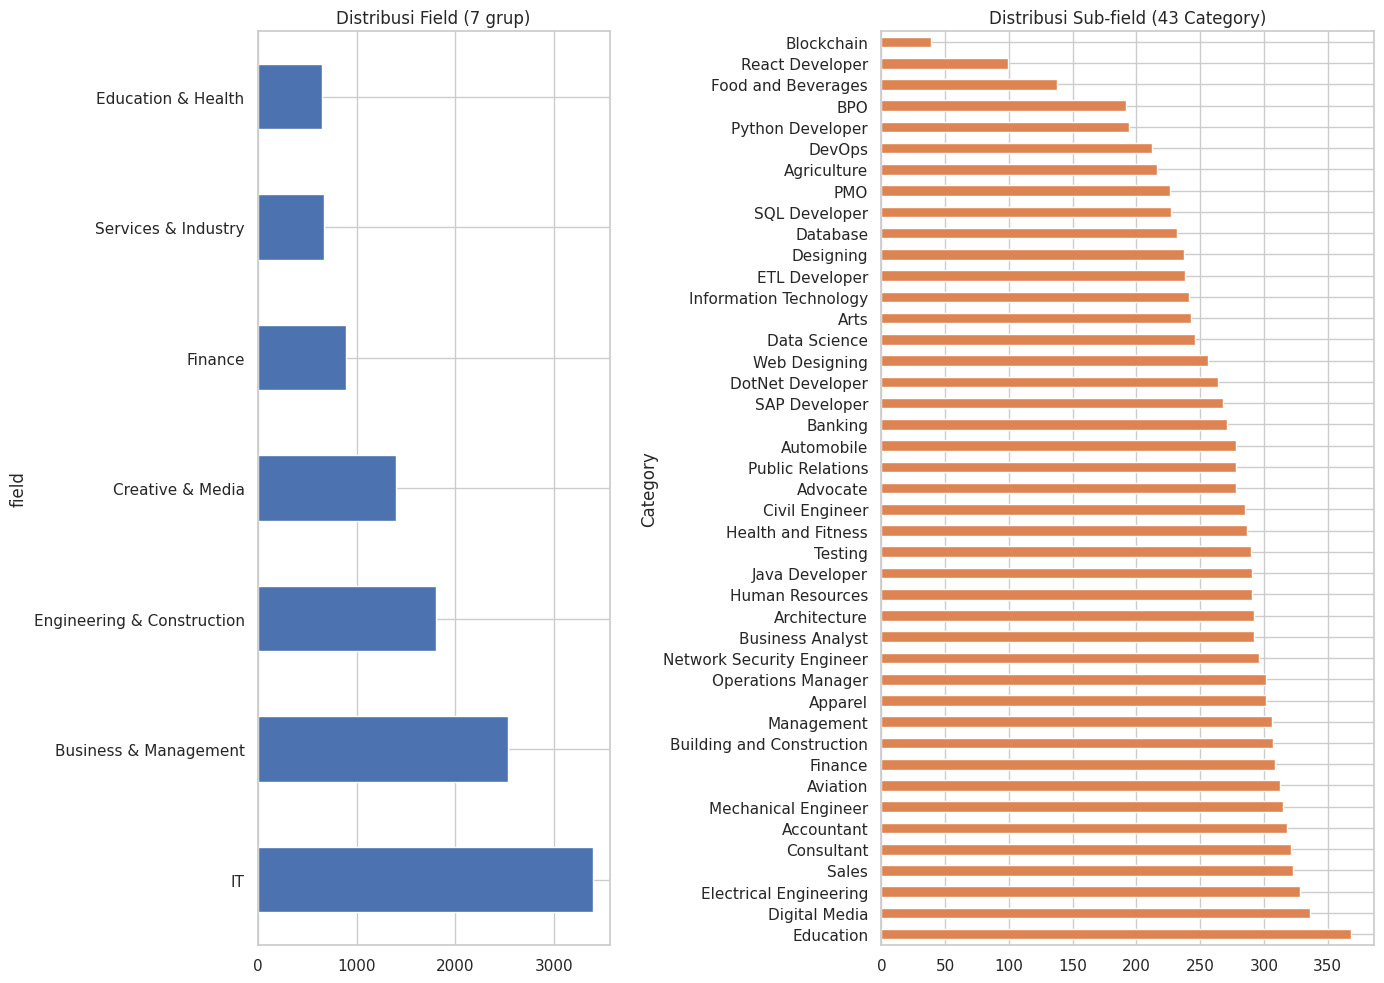

rasio kelas terbanyak/tersedikit: 9.44


In [23]:
fig, ax = plt.subplots(1,2, figsize=(14,10), gridspec_kw={"width_ratios":[1,1.4]})
res.field.value_counts().plot.barh(ax=ax[0], color="C0"); ax[0].set_title("Distribusi Field (7 grup)")
res.Category.value_counts().plot.barh(ax=ax[1], color="C1"); ax[1].set_title("Distribusi Sub-field (43 Category)")
save("t2_label_distribution")
vc = res.Category.value_counts(); print("rasio kelas terbanyak/tersedikit:", round(vc.max()/vc.min(),2))

## 3. Panjang teks

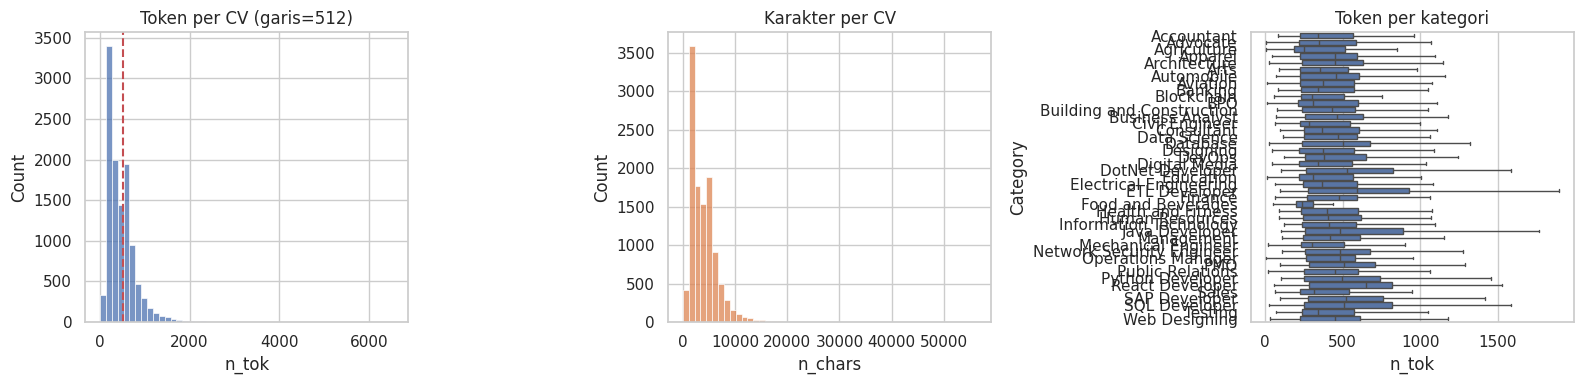

CV > 512 token: 39.8 %


In [24]:
res["n_chars"] = res.text.str.len(); res["n_tok"] = res.text.str.split().str.len()
fig, ax = plt.subplots(1,3, figsize=(16,4))
sns.histplot(res.n_tok, bins=50, ax=ax[0]); ax[0].axvline(512, color="r", ls="--"); ax[0].set_title("Token per CV (garis=512)")
sns.histplot(res.n_chars, bins=50, ax=ax[1], color="C1"); ax[1].set_title("Karakter per CV")
sns.boxplot(data=res, y="Category", x="n_tok", ax=ax[2], showfliers=False); ax[2].set_title("Token per kategori")
save("t2_text_length"); print("CV > 512 token:", round((res.n_tok>512).mean()*100,1), "%")

## 4. Level Seniority (heuristik) & validasi threshold

CV tanpa penyebutan 'N years': 0.532


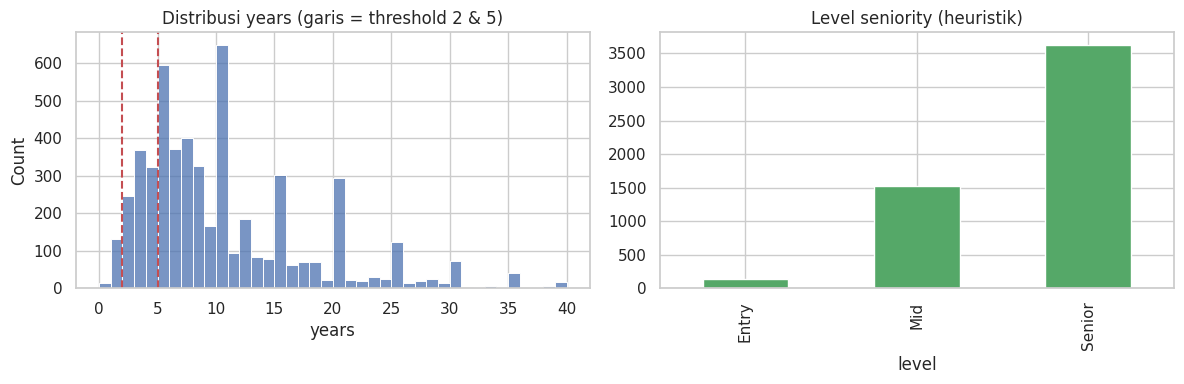

Validasi manual: baca 8 sampel (konteks regex) dan nilai apakah level masuk akal
[Senior] years=21 | ...'lanning daily operations management forward thinking strategic leader 21 years experience serving healthcare education'
[Senior] years=15 | ...'7 graduate computer repair technician uvu orem ut general ed attended 15 years university utah salt lake city ut gener'
[Mid] years=5 | ...'ted troubleshooter deep understanding system architecture diagnostics 5 years total experience skills certification e'
[Senior] years=13 | ...'555 4321000 resumesampleexamplecom summary proactive sr etl developer 13 years carefully handling transforming data lo'
[Mid] years=3 | ...'sampleexamplecom professional summary security analytics professional 3 years experience corporate security possess e'
[Mid] years=4 | ...'omery st 10th floor 555 4321000 resumesampleexamplecom summary around 4 years strong software experience design devel'
[Senior] years=6 | ...'isco ca 94105 555 4321000 resumesampleexampleco

In [25]:
YRS = re.compile(r"(\d{1,2})\s*\+?\s*(?:years?|yrs?)\b", re.I)
def years(t):
    v = [int(x) for x in YRS.findall(t) if int(x) <= 45]
    return max(v) if v else np.nan
res["years"] = res.text.map(years)
res["level"] = res.years.map(lambda y: np.nan if pd.isna(y) else ("Entry" if y<2 else ("Mid" if y<=5 else "Senior")))
print("CV tanpa penyebutan 'N years':", res.years.isna().mean().round(3))
fig, ax = plt.subplots(1,2, figsize=(12,4))
sns.histplot(res.years.dropna(), bins=range(0,41), ax=ax[0]); ax[0].axvline(2,color="r",ls="--"); ax[0].axvline(5,color="r",ls="--"); ax[0].set_title("Distribusi years (garis = threshold 2 & 5)")
res.level.value_counts().reindex(["Entry","Mid","Senior"]).plot.bar(ax=ax[1], color="C2"); ax[1].set_title("Level seniority (heuristik)")
save("t2_seniority")
print("Validasi manual: baca 8 sampel (konteks regex) dan nilai apakah level masuk akal")
for i, r in res.dropna(subset=["years"]).sample(8, random_state=1).iterrows():
    m = [m for m in YRS.finditer(r.text) if int(m.group(1))==r.years][0]
    print(f"[{r.level}] years={int(r.years)} | ...{r.text[max(0,m.start()-70):m.end()+40]!r}")

## 5. Keunikan & duplikasi

In [26]:
print(f"sebelum dedup: {n_raw} | exact-dup dibuang: {n_raw-n_exact} | near-dup (200 char awal) dibuang: {n_exact-n_final} | akhir: {n_final}")
print("teks unik (setelah dedup):", res.text.nunique(), "/", len(res))
d = res[res.text.duplicated(keep=False)]; print("baris dengan teks duplikat:", len(d), "| duplikat dgn label berbeda:", d.groupby("text").Category.nunique().gt(1).sum())

sebelum dedup: 13389 | exact-dup dibuang: 1304 | near-dup (200 char awal) dibuang: 740 | akhir: 11345
teks unik (setelah dedup): 11345 / 11345
baris dengan teks duplikat: 0 | duplikat dgn label berbeda: 0


## 6. Kualitas label & kosakata

Category unik (raw): ['Accountant', 'Advocate', 'Agriculture', 'Apparel', 'Architecture', 'Arts', 'Automobile', 'Aviation', 'BPO', 'Banking', 'Blockchain', 'Building and Construction', 'Business Analyst', 'Civil Engineer', 'Consultant', 'Data Science', 'Database', 'Designing', 'DevOps', 'Digital Media', 'DotNet Developer', 'ETL Developer', 'Education', 'Electrical Engineering', 'Finance', 'Food and Beverages', 'Health and Fitness', 'Human Resources', 'Information Technology', 'Java Developer', 'Management', 'Mechanical Engineer', 'Network Security Engineer', 'Operations Manager', 'PMO', 'Public Relations', 'Python Developer', 'React Developer', 'SAP Developer', 'SQL Developer', 'Sales', 'Testing', 'Web Designing']
label tidak konsisten kapitalisasi/spasi: 0


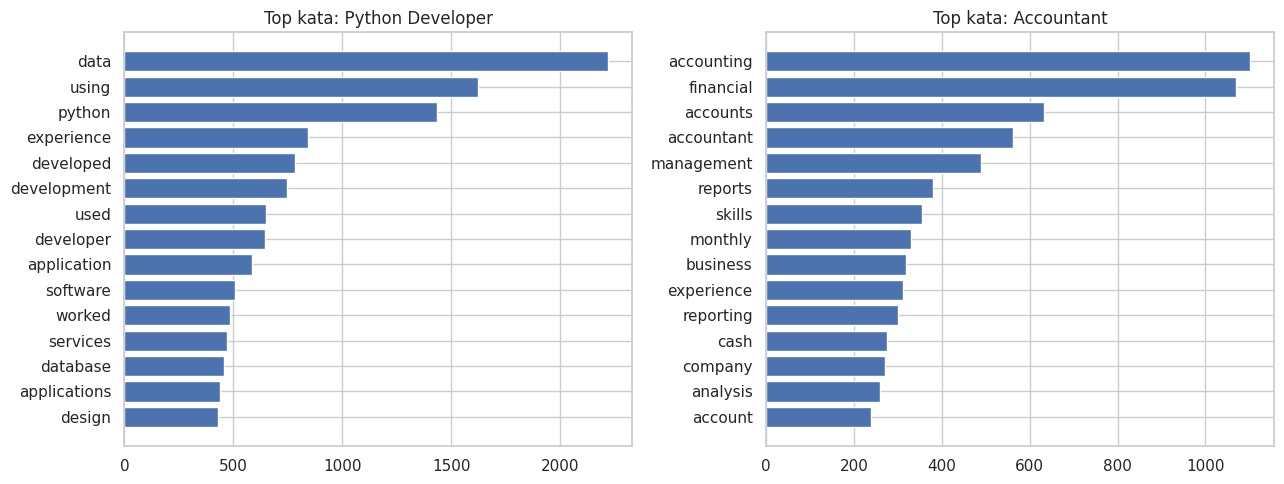

In [27]:
print("Category unik (raw):", sorted(res.Category.unique()))
print("label tidak konsisten kapitalisasi/spasi:", res.Category.nunique() - res.Category.str.lower().nunique())
STOP = set("the and of to in for with a is are on as at by an or from be this that".split())
fig, ax = plt.subplots(1,2, figsize=(13,5))
for a, cat in zip(ax, ["Python Developer","Accountant"]):
    c = collections.Counter(w for t in res[res.Category==cat].text.head(200) for w in re.findall(r"[a-z]{4,}", t.lower()) if w not in STOP).most_common(15)
    a.barh([w for w,_ in c][::-1], [n for _,n in c][::-1]); a.set_title(f"Top kata: {cat}")
save("t2_top_words")

---
# BAGIAN: Task 3 — EDA Matching

In [28]:
%reset -f
import gc; gc.collect()

0

# EDA Task 3 — Matching (resume-ats-score-v1-en)
Kolom asli: `text` (resume + `SEP` + job), `ats_score`, `original_label` (tier). Jumlah di HF: 5099 train + 1275 validation = 6374.

In [29]:
import os, re, json, glob, warnings, collections
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
SEED = 42; np.random.seed(SEED)
FIG, DATA = "../figures", "../data"
os.makedirs(FIG, exist_ok=True); os.makedirs(DATA, exist_ok=True)
os.environ["KAGGLEHUB_CACHE"] = os.path.abspath(f"{DATA}/kaggle")
sns.set_theme(style="whitegrid")
def save(name):
    plt.tight_layout(); plt.savefig(f"{FIG}/{name}.png", dpi=150, bbox_inches="tight"); plt.show()

In [30]:
from datasets import load_dataset
ds = load_dataset("0xnbk/resume-ats-score-v1-en")
df = pd.concat([ds[k].to_pandas().assign(split=k) for k in ds], ignore_index=True)
# kolom 'text' = resume + ' SEP ' + job description (digabung); pisahkan
parts = df["text"].str.split(r"\s+SEP\s+", n=1, regex=True)
df["resume"] = parts.str[0]; df["job"] = parts.str[1].fillna("")
df["tier"] = df["original_label"]
print(df.shape, "| baris tanpa bagian job setelah split:", (df.job == "").sum())

README.md:   0%|          | 0.00/11.8k [00:00<?, ?B/s]

train.csv: reconstructing file:   0%|          |  0.00B / 43.3MB            

train.csv: downloading bytes:           |  0.00B            

validation.csv: reconstructing file:   0%|          |  0.00B / 10.7MB            

validation.csv: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/5099 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1275 [00:00<?, ? examples/s]

(6374, 7) | baris tanpa bagian job setelah split: 0


## 1. Ukuran & struktur

In [31]:
print(df[["ats_score","tier","split"]].describe(include="all").T); print("missing:\n", df[["text","ats_score","original_label"]].isna().sum().to_string())
print("split:", df.split.value_counts().to_dict())

            count unique     top  freq       mean        std    min   25%  \
ats_score  6374.0    NaN     NaN   NaN  47.233478  24.967602  19.16  24.8   
tier         6374      3  No Fit  3206        NaN        NaN    NaN   NaN   
split        6374      2   train  5099        NaN        NaN    NaN   NaN   

            50%   75%    max  
ats_score  29.9  59.8  90.05  
tier        NaN   NaN    NaN  
split       NaN   NaN    NaN  
missing:
 text              0
ats_score         0
original_label    0
split: {'train': 5099, 'validation': 1275}


## 2. Distribusi skor ATS & tier

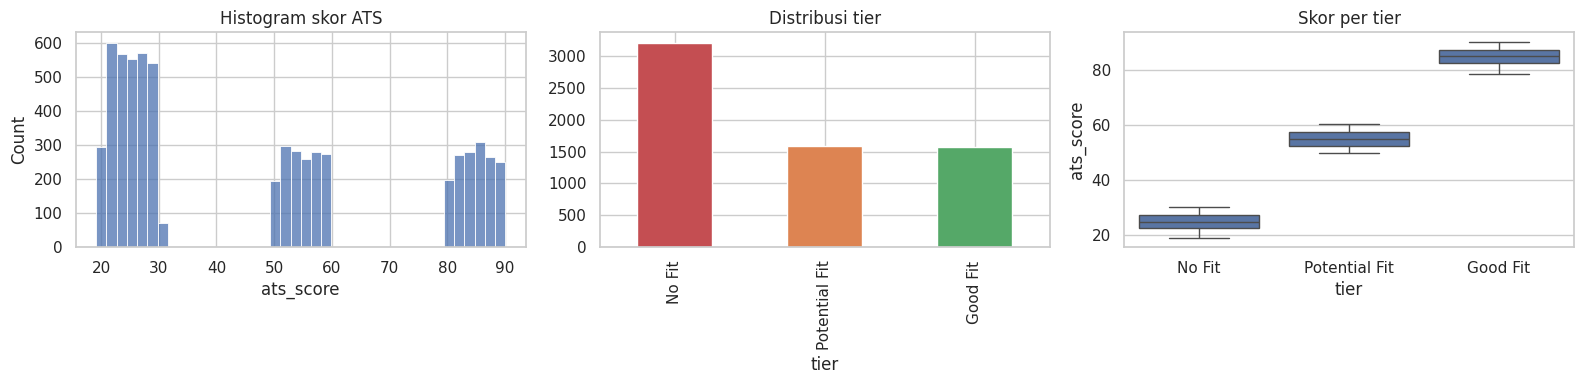

                 min    max   mean  count
tier                                     
Good Fit       78.66  90.05  84.90   1576
No Fit         19.16  30.26  24.95   3206
Potential Fit  50.00  60.36  54.83   1592


In [32]:
fig, ax = plt.subplots(1,3, figsize=(16,4))
sns.histplot(df.ats_score, bins=40, ax=ax[0]); ax[0].set_title("Histogram skor ATS")
df.tier.value_counts().plot.bar(ax=ax[1], color=["C3","C1","C2"]); ax[1].set_title("Distribusi tier")
sns.boxplot(data=df, x="tier", y="ats_score", order=["No Fit","Potential Fit","Good Fit"], ax=ax[2]); ax[2].set_title("Skor per tier")
save("t3_score_tier_distribution")
print(df.groupby("tier").ats_score.agg(["min","max","mean","count"]).round(2))

## 3. Panjang teks

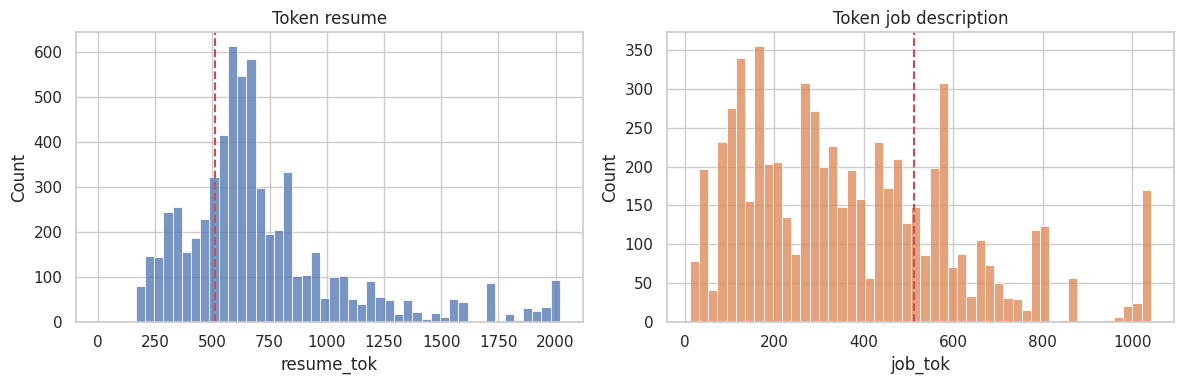

       resume_tok  job_tok
count      6374.0   6374.0
mean        721.0    374.0
std         378.0    242.0
min           4.0     11.0
25%         509.0    169.0
50%         634.0    327.0
75%         827.0    540.0
max        2057.0   1570.0


In [33]:
for c in ["resume","job"]: df[f"{c}_tok"] = df[c].str.split().str.len()
fig, ax = plt.subplots(1,2, figsize=(12,4))
sns.histplot(df.resume_tok.clip(upper=df.resume_tok.quantile(.99)), bins=50, ax=ax[0]); ax[0].axvline(512,color="r",ls="--"); ax[0].set_title("Token resume")
sns.histplot(df.job_tok.clip(upper=df.job_tok.quantile(.99)), bins=50, ax=ax[1], color="C1"); ax[1].axvline(512,color="r",ls="--"); ax[1].set_title("Token job description")
save("t3_text_length"); print(df[["resume_tok","job_tok"]].describe().round(0))

## 4. Kata dominan & keyword overlap vs skor

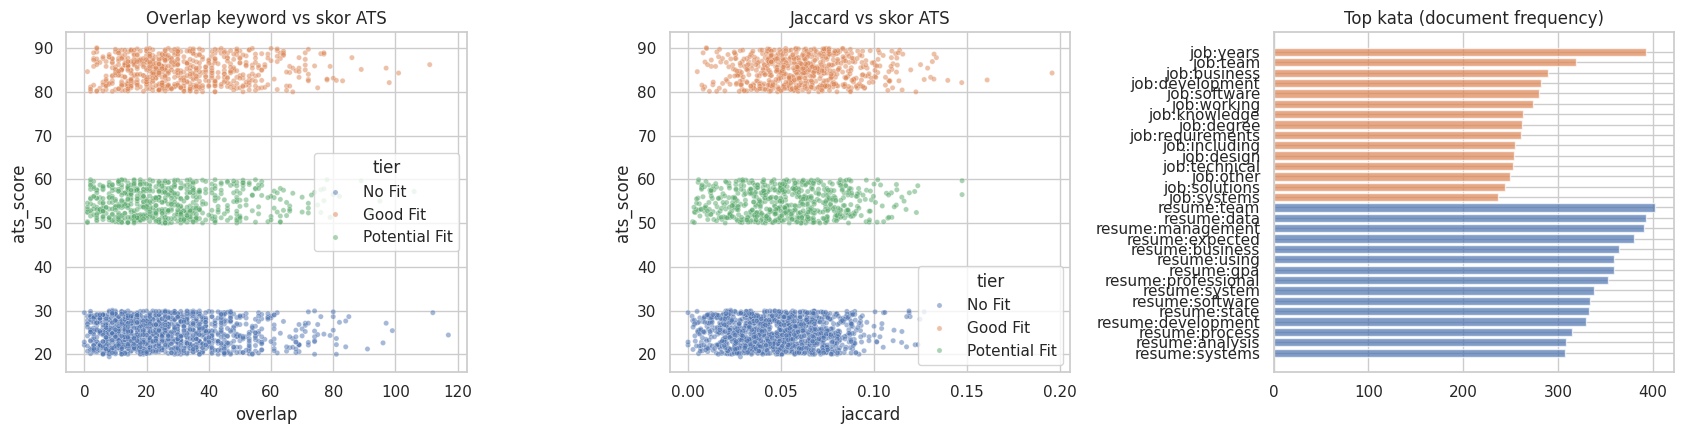

Spearman overlap~skor: 0.123 | jaccard~skor: 0.185


In [34]:
STOP = set("the and of to in for with a is are on as at by an or from be this that will your you our we have has can all new job work experience skills".split())
tok = lambda t: set(w for w in re.findall(r"[a-z][a-z+#.]{2,}", t.lower()) if w not in STOP)
T = [(tok(r), tok(j)) for r, j in zip(df.resume, df.job)]
df["overlap"] = [len(a & b) for a, b in T]; df["jaccard"] = [len(a & b)/max(1, len(a | b)) for a, b in T]
s = df.sample(2500, random_state=1)
fig, ax = plt.subplots(1,3, figsize=(17,4.5))
sns.scatterplot(data=s, x="overlap", y="ats_score", hue="tier", alpha=.5, s=14, ax=ax[0]); ax[0].set_title("Overlap keyword vs skor ATS")
sns.scatterplot(data=s, x="jaccard", y="ats_score", hue="tier", alpha=.5, s=14, ax=ax[1]); ax[1].set_title("Jaccard vs skor ATS")
for k, col in [("resume","C0"),("job","C1")]:
    c = collections.Counter(w for t in df[k].sample(500, random_state=1) for w in tok(t)).most_common(15)
    ax[2].barh([f"{k}:{w}" for w,_ in c][::-1], [n for _,n in c][::-1], color=col, alpha=.7)
ax[2].set_title("Top kata (document frequency)")
save("t3_overlap_vs_score")
print("Spearman overlap~skor:", round(df.overlap.corr(df.ats_score, method="spearman"),3), "| jaccard~skor:", round(df.jaccard.corr(df.ats_score, method="spearman"),3))

## 5. Duplikasi / keunikan

In [35]:
print("resume unik:", df.resume.nunique(), "/", len(df)); print("job unik:", df.job.nunique(), "/", len(df)); print("pasangan unik:", df.text.nunique())
g = df.groupby("job").size(); print("job yang dipakai >1 resume:", (g>1).sum(), "| max resume per job:", g.max())
print("pasangan identik dgn label ganda:", (df.groupby("text").tier.nunique()>1).sum())

resume unik: 778 / 6374
job unik: 320 / 6374
pasangan unik: 6374
job yang dipakai >1 resume: 277 | max resume per job: 112
pasangan identik dgn label ganda: 0


## 6. Kualitas data

In [36]:
print("tier unik:", df.tier.unique())
print("skor di luar [18,90]:", ((df.ats_score<18)|(df.ats_score>90)).sum(), "| range aktual:", df.ats_score.min(), df.ats_score.max())
print("job kosong setelah split SEP:", (df.job.str.len()<30).sum(), "| resume < 100 char:", (df.resume.str.len()<100).sum())
print("batas skor per tier (cek tumpang tindih):\n", df.groupby("tier").ats_score.agg(["min","max"]))

tier unik: ['Good Fit' 'No Fit' 'Potential Fit']
skor di luar [18,90]: 1 | range aktual: 19.16 90.05
job kosong setelah split SEP: 0 | resume < 100 char: 1
batas skor per tier (cek tumpang tindih):
                  min    max
tier                       
Good Fit       78.66  90.05
No Fit         19.16  30.26
Potential Fit  50.00  60.36


---
# BAGIAN: Task 1 — Eksperimen NER

In [37]:
%reset -f
import gc; gc.collect()

0

# Eksperimen Task 1 — NER
Bandingkan: (1) rule-based + gazetteer, (2) CRF fitur manual, (3) fine-tuned BERT-NER. Metrik: Precision/Recall/F1 **per entity type** (exact-span match). Skala kecil untuk checkpoint.

Catatan desain: tokenisasi regex → BIO; span anotasi > 60 karakter di-skip (umumnya blob section 'Skills', lihat EDA); label `OTHER` di-drop.

In [38]:
import os, re, json, glob, warnings, collections
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
SEED = 42; np.random.seed(SEED)
FIG, DATA = "../figures", "../data"
os.makedirs(FIG, exist_ok=True); os.makedirs(DATA, exist_ok=True)
os.environ["KAGGLEHUB_CACHE"] = os.path.abspath(f"{DATA}/kaggle")
sns.set_theme(style="whitegrid")
def save(name):
    plt.tight_layout(); plt.savefig(f"{FIG}/{name}.png", dpi=150, bbox_inches="tight"); plt.show()

N_DOCS, MAX_SPAN = 1200, 60   # sample CV untuk eksperimen
BERT_DOCS, BERT_EPOCHS = 300, 2

In [39]:
import kagglehub
p = kagglehub.dataset_download("yashpwrr/resume-ner-training-dataset")
cv = json.load(open(glob.glob(f"{p}/**/train.json", recursive=True)[0], encoding="utf8"))
SURR = re.compile("[" + chr(0xd800) + "-" + chr(0xdfff) + "]")  # lone surrogate di sebagian teks -> ganti 1:1 (offset anotasi tetap valid)
n_bad = sum(bool(SURR.search(x["text"])) for x in cv)
for x in cv: x["text"] = SURR.sub(chr(0xfffd), x["text"])
print(len(cv), "CV |", n_bad, "CV mengandung karakter surrogate rusak (dibersihkan)")

5960 CV | 1 CV mengandung karakter surrogate rusak (dibersihkan)


## Data → BIO

In [40]:
TOK = re.compile(r"[\w.+-]+@[\w-]+(?:\.[\w-]+)+|\w+(?:[.+#'-]\w+)*|[^\w\s]")
def to_bio(item):
    text = item["text"]; toks = [(m.group(), m.start(), m.end()) for m in TOK.finditer(text)]
    tags = ["O"]*len(toks)
    for s, e, lab in sorted(item["annotations"]):
        if lab == "OTHER" or e - s > MAX_SPAN or e <= s: continue
        idx = [i for i,(_,a,b) in enumerate(toks) if a >= s and b <= e]
        if not idx or any(tags[i] != "O" for i in idx): continue
        tags[idx[0]] = "B-"+lab
        for i in idx[1:]: tags[i] = "I-"+lab
    return [t for t,_,_ in toks], tags
rng = np.random.RandomState(SEED); sel = rng.choice(len(cv), N_DOCS, replace=False)
data = [to_bio(cv[i]) for i in sel]
ntr = int(.8*len(data)); train, test = data[:ntr], data[ntr:]
LABELS = sorted({t[2:] for _, ts in data for t in ts if t != "O"}); print(LABELS, len(train), len(test))

def spans(tags):
    out, cur = set(), None
    for i, t in enumerate(tags + ["O"]):
        if cur and not t.startswith("I-"): out.add((cur[0], cur[1], i)); cur = None
        if t.startswith("B-") or (t.startswith("I-") and cur is None): cur = (t[2:], i)
    return out
def evaluate(gold, pred, name):
    tp, fp, fn = collections.Counter(), collections.Counter(), collections.Counter()
    for g, p in zip(gold, pred):
        G, P = spans(g), spans(p)
        for l,*_ in G & P: tp[l]+=1
        for l,*_ in P - G: fp[l]+=1
        for l,*_ in G - P: fn[l]+=1
    rows = []
    for l in LABELS + ["__micro__"]:
        a, b, c = (sum(tp.values()), sum(fp.values()), sum(fn.values())) if l=="__micro__" else (tp[l], fp[l], fn[l])
        P_, R_ = a/max(1,a+b), a/max(1,a+c); rows.append((l, P_, R_, 2*P_*R_/max(1e-9,P_+R_), a+c))
    return pd.DataFrame(rows, columns=["entity","P","R","F1","support"]).assign(model=name)
RESULTS = []

['ACTION', 'CERTIFICATION', 'COLLABORATION', 'COMPANY', 'DESIGNATION', 'EDUCATION', 'EMAIL', 'EXPERIENCE', 'EXPERTISE', 'LANGUAGE', 'LOCATION', 'PERSON', 'SKILL'] 960 240


## 1. Baseline rule-based + gazetteer

In [41]:
gaz = collections.defaultdict(collections.Counter)
for toks, tags in train:
    for l, s, e in spans(tags): gaz[l][tuple(w.lower() for w in toks[s:e])] += 1
# gazetteer: entri muncul >=2x di train; PERSON/EMAIL ditangani regex (tipe terbuka)
GZ = {l: {k for k,c in cnt.items() if c>=2} for l,cnt in gaz.items() if l not in ("PERSON","EMAIL")}
MAXLEN = max((len(k) for s in GZ.values() for k in s), default=1)
EMAIL = re.compile(r"^[\w.+-]+@[\w-]+\.[\w.]+$"); EXP = re.compile(r"^\d+\+?$")
prio = ["SKILL","DESIGNATION","EDUCATION","LOCATION","COMPANY","EXPERTISE","LANGUAGE","CERTIFICATION","COLLABORATION","ACTION"]
def rule_predict(toks):
    tags, i = ["O"]*len(toks), 0
    low = [t.lower() for t in toks]
    while i < len(toks):
        if "@" in toks[i] and EMAIL.match(toks[i]): tags[i] = "B-EMAIL"; i += 1; continue
        if EXP.match(toks[i]) and i+1 < len(toks) and low[i+1] in ("years","year","yrs"):
            tags[i] = "B-EXPERIENCE"; tags[i+1] = "I-EXPERIENCE"; i += 2; continue
        hit = None
        for n in range(min(MAXLEN, len(toks)-i), 0, -1):
            k = tuple(low[i:i+n])
            for l in prio:
                if l in GZ and k in GZ[l]: hit = (l, n); break
            if hit: break
        if hit:
            l, n = hit; tags[i] = "B-"+l
            for j in range(1, n): tags[i+j] = "I-"+l
            i += n
        else: i += 1
    return tags
rule_pred = [rule_predict(t) for t,_ in test]
r = evaluate([t for _,t in test], rule_pred, "Rule+Gazetteer"); RESULTS.append(r); display(r.round(3))

,entity,P,R,F1,support,model
0,ACTION,0.000,0.000,0.000,5,Rule+Gazetteer
1,CERTIFICATION,0.000,0.000,0.000,3,Rule+Gazetteer
2,COLLABORATION,0.000,0.000,0.000,5,Rule+Gazetteer
3,COMPANY,0.053,0.091,0.067,11,Rule+Gazetteer
4,DESIGNATION,0.100,0.088,0.093,261,Rule+Gazetteer
5,EDUCATION,0.011,0.101,0.020,109,Rule+Gazetteer
6,EMAIL,0.129,0.609,0.213,46,Rule+Gazetteer
7,EXPERIENCE,0.043,0.034,0.038,207,Rule+Gazetteer
8,EXPERTISE,0.000,0.000,0.000,23,Rule+Gazetteer
9,LANGUAGE,0.000,0.000,0.000,6,Rule+Gazetteer


## 2. CRF (fitur manual: capitalization, shape, affix, POS, context window ±2)

In [ ]:
import nltk
try:
    for r_ in ["averaged_perceptron_tagger_eng","averaged_perceptron_tagger"]: nltk.download(r_, quiet=True)
    nltk.pos_tag(["test"]); HAS_POS = True
except Exception as ex: HAS_POS = False; print("POS tagger tidak tersedia, fitur POS dilewati:", ex)
def shape(w): return re.sub(r"[a-z]+","a",re.sub(r"[A-Z]+","A",re.sub(r"\d+","0",w)))[:6]
def feats(toks):
    pos = [p for _,p in nltk.pos_tag(toks)] if HAS_POS else ["_"]*len(toks)
    F = []
    for i, w in enumerate(toks):
        f = {"b":1, "w":w.lower(), "up":w.isupper(), "ti":w.istitle(), "dg":w.isdigit(), "sh":shape(w), "p3":w[-3:].lower(), "s3":w[:3].lower(), "pos":pos[i], "at":"@" in w}
        for d in (-2,-1,1,2):
            j = i+d
            if 0 <= j < len(toks): f.update({f"{d}:w":toks[j].lower(), f"{d}:ti":toks[j].istitle(), f"{d}:pos":pos[j]})
            else: f[f"{d}:pad"] = True
        F.append(f)
    return F
import sklearn_crfsuite
Xtr = [feats(t) for t,_ in train]; Xte = [feats(t) for t,_ in test]
crf = sklearn_crfsuite.CRF(algorithm="lbfgs", c1=.1, c2=.1, max_iterations=80, all_possible_transitions=True)
crf.fit(Xtr, [t for _,t in train]); crf_pred = crf.predict(Xte)
r = evaluate([t for _,t in test], crf_pred, "CRF"); RESULTS.append(r); display(r.round(3))

## 3. Fine-tuned BERT-NER (`dslim/bert-base-NER`, sample kecil)

In [ ]:
RUN_BERT = os.environ.get("RUN_BERT", "1") == "1"   # set "0" untuk melewati fine-tuning BERT (lambat di CPU)
if not RUN_BERT: print("RUN_BERT=0 -> BERT dilewati")
if RUN_BERT:
  import torch
  from transformers import AutoTokenizer, AutoModelForTokenClassification
  BERT = "dslim/bert-base-NER"; dev = "cuda" if torch.cuda.is_available() else "cpu"
  tags_all = ["O"] + [f"{p}-{l}" for l in LABELS for p in "BI"]; t2i = {t:i for i,t in enumerate(tags_all)}
  tk = AutoTokenizer.from_pretrained(BERT)
  model = AutoModelForTokenClassification.from_pretrained(BERT, num_labels=len(tags_all), id2label=dict(enumerate(tags_all)), label2id=t2i, ignore_mismatched_sizes=True).to(dev)
  WIN = 100  # kata per chunk -> aman < 256 subword
  def chunks(data):
      for toks, tags in data:
          for i in range(0, len(toks), WIN): yield toks[i:i+WIN], tags[i:i+WIN]
  def enc(batch):
      e = tk([b[0] for b in batch], is_split_into_words=True, truncation=True, max_length=256, padding=True, return_tensors="pt")
      labs = []
      for bi, (toks, tags) in enumerate(batch):
          prev, row = None, []
          for w in e.word_ids(bi):
              row.append(-100 if w is None or w == prev else t2i[tags[w]]); prev = w
          labs.append(row)
      return e, torch.tensor(labs)
  tr_chunks = list(chunks(train[:BERT_DOCS])); opt = torch.optim.AdamW(model.parameters(), lr=3e-5)
  model.train()
  for ep in range(BERT_EPOCHS):
      perm = np.random.permutation(len(tr_chunks)); tot = 0
      for i in range(0, len(perm), 8):
          e, y = enc([tr_chunks[j] for j in perm[i:i+8]])
          out = model(**{k:v.to(dev) for k,v in e.items()}, labels=y.to(dev)); out.loss.backward(); opt.step(); opt.zero_grad(); tot += out.loss.item()
      print("epoch", ep+1, "loss", round(tot/(len(perm)/8),4))
  @torch.no_grad()
  def bert_predict(toks_list):
      model.eval(); res_ = []
      for toks in toks_list:
          pred = []
          for i in range(0, len(toks), WIN):
              c = toks[i:i+WIN]; e = tk([c], is_split_into_words=True, truncation=True, max_length=256, return_tensors="pt")
              lg = model(**{k:v.to(dev) for k,v in e.items()}).logits[0].argmax(-1).cpu().tolist(); wid = e.word_ids(0); out, prev = ["O"]*len(c), None
              for p, w in zip(lg, wid):
                  if w is not None and w != prev: out[w] = tags_all[p]
                  prev = w
              pred += out
          res_.append(pred)
      return res_
  bert_pred = bert_predict([t for t,_ in test])
  r = evaluate([t for _,t in test], bert_pred, "BERT"); RESULTS.append(r); display(r.round(3))

## Perbandingan per entity type

In [ ]:
allr = pd.concat(RESULTS); allr.to_csv(f"{DATA}/t1_results.csv", index=False)
piv = allr.pivot(index="entity", columns="model", values="F1"); display(piv.round(3))
piv.drop("__micro__").plot.bar(figsize=(12,4.5)); plt.ylabel("F1 (exact span)"); plt.title("Task 1 — F1 per entity type"); plt.xticks(rotation=30, ha="right")
save("t1_exp_f1_per_entity")

## Domain shift: CV vs Job Description
Dataset job description **tidak punya gold NER**, jadi F1 tidak bisa dihitung. Yang dilakukan: bandingkan densitas entity prediksi per 1000 token pada CV test vs job posting. Untuk F1 sebenarnya perlu anotasi manual ±50 job posting.

In [ ]:
import kagglehub, pyarrow.parquet as pq
pj = kagglehub.dataset_download("khaliladimassi/cleaned-job-description")
JOB_N = 300  # ukuran sample job posting (dari 159.589 baris file asli)
job = pq.read_table(glob.glob(f"{pj}/**/cleaned_jobs_desc.parquet", recursive=True)[0], columns=["job_title","company_name","job_description"]).to_pandas()
print("total baris job file:", len(job))
job = job.sample(JOB_N, random_state=SEED).reset_index(drop=True)
print("sample dipakai:", len(job))

In [ ]:
job_toks = [TOK.findall(str(t))[:600] for t in job.job_description.fillna("")]
models = {"Rule+Gazetteer": lambda L: [rule_predict(t) for t in L], "CRF": lambda L: crf.predict([feats(t) for t in L])}
if RUN_BERT: models["BERT"] = bert_predict
rows = []
for name, fn in models.items():
    for dom, L in [("CV (test)", [t[:600] for t,_ in test[:100]]), ("Job desc", job_toks[:100])]:
        P = fn(L); n = sum(len(t) for t in L); c = collections.Counter(l for p in P for l,_,_ in spans(p))
        rows.append({"model":name, "domain":dom, "entities/1k tok": 1000*sum(c.values())/n, **{k: 1000*v/n for k,v in c.items()}})
shift = pd.DataFrame(rows); display(shift.fillna(0).round(2)); shift.to_csv(f"{DATA}/t1_domain_shift.csv", index=False)
sns.barplot(data=shift, x="model", y="entities/1k tok", hue="domain"); plt.title("Densitas entity prediksi: CV vs Job Desc"); save("t1_exp_domain_shift")

---
# BAGIAN: Task 2 — Eksperimen Classification

In [ ]:
%reset -f
import gc; gc.collect()

# Eksperimen Task 2 — Classification
Output: Field (7), Sub-field (43 Category, ResumeAtlas), Level (Entry/Mid/Senior heuristik). Pendekatan: (1) 3 classifier independen TF-IDF + LR/SVM, (2) hierarchical Field → Sub-field. (3) BERT multi-output = opsional, **tidak dijalankan** di checkpoint ini.

Label Field/Level diturunkan seperti di `eda_task2_classification.ipynb` (FIELD_MAP = asumsi).

In [ ]:
import os, re, json, glob, warnings, collections
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
SEED = 42; np.random.seed(SEED)
FIG, DATA = "../figures", "../data"
os.makedirs(FIG, exist_ok=True); os.makedirs(DATA, exist_ok=True)
os.environ["KAGGLEHUB_CACHE"] = os.path.abspath(f"{DATA}/kaggle")
sns.set_theme(style="whitegrid")
def save(name):
    plt.tight_layout(); plt.savefig(f"{FIG}/{name}.png", dpi=150, bbox_inches="tight"); plt.show()

In [ ]:
from datasets import load_dataset
res = load_dataset("ahmedheakl/resume-atlas")["train"].to_pandas().rename(columns={"Text": "text"})
res["text"] = res["text"].fillna(""); res["Category"] = res["Category"].astype(str).str.strip()
# WAJIB dedup sebelum split (CV template/near-duplicate -> kebocoran train/test)
n_raw = len(res)
norm = res.text.str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
res = res[~norm.duplicated()]; n_exact = len(res)
res = res[~res.text.str.lower().str[:200].duplicated()].reset_index(drop=True); n_final = len(res)  # near-duplicate: 200 karakter awal sama
print(f"raw={n_raw} -> setelah dedup exact={n_exact} -> setelah dedup near-dup(200 char awal)={n_final}  (dibuang {n_raw-n_final}, {100*(n_raw-n_final)/n_raw:.1f}%)")

In [ ]:
FIELD_MAP = {  # mapping manual 43 kategori ResumeAtlas (Sub-bidang) -> 7 Bidang (ASUMSI; sesuaikan dgn desain laporan)
 **{k: "IT" for k in ["Java Developer","Python Developer","DotNet Developer","SQL Developer","SAP Developer","ETL Developer","React Developer",
    "Web Designing","Database","DevOps","Testing","Network Security Engineer","Data Science","Blockchain","Information Technology"]},
 **{k: "Engineering & Construction" for k in ["Electrical Engineering","Mechanical Engineer","Civil Engineer","Building and Construction","Architecture","Automobile"]},
 **{k: "Finance" for k in ["Accountant","Finance","Banking"]},
 **{k: "Business & Management" for k in ["Business Analyst","Consultant","Management","Operations Manager","PMO","Sales","Human Resources","BPO","Advocate"]},
 **{k: "Creative & Media" for k in ["Designing","Digital Media","Arts","Apparel","Public Relations"]},
 **{k: "Education & Health" for k in ["Education","Health and Fitness"]},
 **{k: "Services & Industry" for k in ["Food and Beverages","Aviation","Agriculture"]}}
YRS = re.compile(r"(\d{1,2})\s*\+?\s*(?:years?|yrs?)\b", re.I)
def years(t):
    v = [int(x) for x in YRS.findall(t) if int(x) <= 45]; return max(v) if v else np.nan
res["sub"] = res.Category; res["field"] = res["sub"].map(FIELD_MAP)
res["years"] = res.text.map(years)
res["level"] = res.years.map(lambda y: np.nan if pd.isna(y) else ("Entry" if y<2 else ("Mid" if y<=5 else "Senior")))
res = res.dropna(subset=["field"]).reset_index(drop=True)  # dedup sudah di cell load
print(len(res), "| level terisi:", res.level.notna().sum())
from sklearn.model_selection import train_test_split
tr, te = train_test_split(res, test_size=.2, random_state=SEED, stratify=res["sub"])
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
vec = TfidfVectorizer(max_features=30000, ngram_range=(1,2), sublinear_tf=True, min_df=2, stop_words="english")
Xtr, Xte = vec.fit_transform(tr.text), vec.transform(te.text)
# catatan: teks mentah memuat kata judul pekerjaan (hampir pasti membocorkan label kategori) -> hasil optimistis; bahas di laporan.
RES = []
def log(name, out, y, p):
    RES.append({"approach":name, "output":out, "acc":accuracy_score(y,p), "macro_F1":f1_score(y,p,average="macro")})

## 1. Baseline: 3 classifier independen (LR vs LinearSVC)

In [ ]:
P1 = {}
for cname, mk in [("LR", lambda: LogisticRegression(max_iter=300, C=5)), ("SVM", lambda: LinearSVC(C=1))]:
    for out in ["field","sub","level"]:
        m_tr = tr[out].notna().values; m_te = te[out].notna().values
        clf = mk().fit(Xtr[m_tr], tr[out][m_tr]); p = pd.Series(np.nan, index=te.index, dtype=object); p[m_te] = clf.predict(Xte[m_te])
        P1[(cname,out)] = p; log(f"Independen-{cname}", out, te[out][m_te], p[m_te])
display(pd.DataFrame(RES).round(3))

## 2. Hierarchical: Field → Sub-field | Field

In [ ]:
fclf = LogisticRegression(max_iter=300, C=5).fit(Xtr, tr.field); pf = fclf.predict(Xte)
sub_clf = {}
for f in tr.field.unique():
    mk_ = (tr.field==f).values
    sub_clf[f] = LogisticRegression(max_iter=300, C=5).fit(Xtr[mk_], tr["sub"][mk_]) if tr["sub"][mk_].nunique()>1 else tr["sub"][mk_].iloc[0]
ps = np.array([sub_clf[f].predict(Xte[i])[0] if hasattr(sub_clf[f], "predict") else sub_clf[f] for i, f in enumerate(pf)])
log("Hierarchical", "field", te.field, pf); log("Hierarchical", "sub", te["sub"], ps)
m_te = te.level.notna().values
lclf = LogisticRegression(max_iter=300, C=5).fit(Xtr[tr.level.notna().values], tr.level.dropna()); pl = pd.Series(np.nan, index=te.index, dtype=object); pl[m_te] = lclf.predict(Xte[m_te])
log("Hierarchical", "level", te.level[m_te], pl[m_te])
inc = lambda sub, fld: round((pd.Series(sub, index=te.index).map(FIELD_MAP) != pd.Series(fld, index=te.index)).mean()*100, 2)
print("inkonsistensi sub vs field -> independen LR:", inc(P1[("LR","sub")], P1[("LR","field")]), "% | hierarchical:", inc(ps, pf), "%")

## Evaluasi: per output + exact match (ketiganya benar; hanya baris dengan level terisi)

In [ ]:
S = lambda x: pd.Series(x, index=te.index)
em = {f"Independen-{c}": ((P1[(c,'field')]==te.field) & (P1[(c,'sub')]==te['sub']) & (P1[(c,'level')]==te.level))[m_te].mean() for c in ["LR","SVM"]}
em["Hierarchical"] = ((S(pf)==te.field) & (S(ps)==te["sub"]) & (pl==te.level))[m_te].mean()
out = pd.DataFrame(RES); out.to_csv(f"{DATA}/t2_results.csv", index=False)
tab = out.pivot(index="approach", columns="output", values="macro_F1"); tab["exact_match"] = pd.Series(em); display(tab.round(3))
tab.plot.bar(figsize=(9,4.5)); plt.ylim(0,1); plt.title("Task 2 — macro-F1 per output & exact match"); plt.xticks(rotation=0); save("t2_exp_comparison")
print(classification_report(te["sub"], ps, zero_division=0))
L3 = ["Entry","Mid","Senior"]
sns.heatmap(confusion_matrix(te.level[m_te], pl[m_te], labels=L3), annot=True, fmt="d", xticklabels=L3, yticklabels=L3, cmap="Blues"); plt.title("Confusion Level (LR)"); save("t2_exp_level_confusion")

## Validasi manual threshold seniority (2 & 5 tahun)
Baca sampel di sekitar threshold dan nilai apakah 'N years' benar-benar total pengalaman kerja.

In [ ]:
near = res[res.years.isin([1,2,3,5,6])].groupby("years").sample(3, random_state=2)
for _, r in near.iterrows():
    m = [m for m in YRS.finditer(r.text) if int(m.group(1))==r.years][0]
    print(f"years={int(r.years)} -> {r.level:6s} | ...{r.text[max(0,m.start()-80):m.end()+50]!r}")
print("\nCatat di laporan: berapa dari sampel ini yang benar. Masalah umum: 'N years' bisa merujuk durasi satu job, bukan total pengalaman.")

---
# BAGIAN: Task 3 — Eksperimen Matching

In [ ]:
%reset -f
import gc; gc.collect()

# Eksperimen Task 3 — Matching
Bandingkan: (1) TF-IDF cosine baseline, (2) regresi skor ATS, (3) klasifikasi 3-tier. Evaluasi: MAE/RMSE, P/R/F1 per tier, NDCG & MRR.

In [ ]:
import os, re, json, glob, warnings, collections
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
SEED = 42; np.random.seed(SEED)
FIG, DATA = "../figures", "../data"
os.makedirs(FIG, exist_ok=True); os.makedirs(DATA, exist_ok=True)
os.environ["KAGGLEHUB_CACHE"] = os.path.abspath(f"{DATA}/kaggle")
sns.set_theme(style="whitegrid")
def save(name):
    plt.tight_layout(); plt.savefig(f"{FIG}/{name}.png", dpi=150, bbox_inches="tight"); plt.show()

In [ ]:
from datasets import load_dataset
ds = load_dataset("0xnbk/resume-ats-score-v1-en")
df = pd.concat([ds[k].to_pandas().assign(split=k) for k in ds], ignore_index=True)
# kolom 'text' = resume + ' SEP ' + job description (digabung); pisahkan
parts = df["text"].str.split(r"\s+SEP\s+", n=1, regex=True)
df["resume"] = parts.str[0]; df["job"] = parts.str[1].fillna("")
df["tier"] = df["original_label"]
print(df.shape, "| baris tanpa bagian job setelah split:", (df.job == "").sum())

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge, LogisticRegression, LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, classification_report, precision_recall_fscore_support, ndcg_score
from scipy.sparse import hstack, csr_matrix
df = df[df.job.str.len() > 30].reset_index(drop=True)
# EDA: hanya 320 job & 778 resume unik dari 6374 pasangan -> split bawaan bocor (job/resume sama di train & val).
# Split per job (GroupShuffleSplit) supaya evaluasi jujur untuk job yang belum pernah dilihat.
from sklearn.model_selection import GroupShuffleSplit
i_tr, i_te = next(GroupShuffleSplit(1, test_size=.2, random_state=SEED).split(df, groups=df.job))
tr, te = df.iloc[i_tr].reset_index(drop=True), df.iloc[i_te].reset_index(drop=True)
TIERS = ["No Fit","Potential Fit","Good Fit"]
vec = TfidfVectorizer(max_features=40000, ngram_range=(1,2), sublinear_tf=True, min_df=3, stop_words="english").fit(pd.concat([tr.resume, tr.job]))
def feats(d):
    R, J = vec.transform(d.resume), vec.transform(d.job)
    return R, J, np.asarray(R.multiply(J).sum(1)).ravel()   # tf-idf L2-normalized -> dot = cosine
Rtr, Jtr, ctr = feats(tr); Rte, Jte, cte = feats(te)
# fitur interaksi: elemen-wise product (term yang muncul di resume & job) + cosine
Xtr = hstack([Rtr.multiply(Jtr), csr_matrix(ctr[:,None])]).tocsr(); Xte = hstack([Rte.multiply(Jte), csr_matrix(cte[:,None])]).tocsr()
print(len(tr), len(te))

## 1. Baseline TF-IDF cosine
Skor = cosine, dikalibrasi ke skala ATS lewat regresi 1-fitur; tier lewat threshold kuantil dari train.

In [ ]:
cal = LinearRegression().fit(ctr[:,None], tr.ats_score); p_base = np.clip(cal.predict(cte[:,None]), 18, 90)
q = np.quantile(ctr, [tr.tier.eq("No Fit").mean(), tr.tier.isin(["No Fit","Potential Fit"]).mean()])
tier_base = np.where(cte < q[0], "No Fit", np.where(cte < q[1], "Potential Fit", "Good Fit"))
print("Spearman(cosine, ats_score):", round(pd.Series(cte).corr(te.ats_score, method="spearman"),3))

## 2. Regresi skor ATS (Ridge)  &  3. Klasifikasi tier (Logistic Regression)

In [ ]:
reg = Ridge(alpha=1.0).fit(Xtr, tr.ats_score); p_reg = np.clip(reg.predict(Xte), 18, 90)
clf = LogisticRegression(max_iter=500, C=5, class_weight="balanced").fit(Xtr, tr.tier); tier_clf = clf.predict(Xte)
b = [tr[tr.tier==t].ats_score for t in TIERS]; th = [(b[0].max()+b[1].min())/2, (b[1].max()+b[2].min())/2]
tier_reg = np.where(p_reg < th[0], "No Fit", np.where(p_reg < th[1], "Potential Fit", "Good Fit"))  # tier turunan dari regresi
print("threshold tier dari skor:", np.round(th,1))
rows = [{"model":n, "MAE":mean_absolute_error(te.ats_score,p), "RMSE":mean_squared_error(te.ats_score,p)**.5} for n, p in
        [("Mean konstan", np.full(len(te), tr.ats_score.mean())), ("TF-IDF cosine", p_base), ("Ridge regresi", p_reg)]]
reg_tab = pd.DataFrame(rows); display(reg_tab.round(3))
cls = []
for n, t in [("TF-IDF cosine (threshold)", tier_base), ("Ridge -> tier", tier_reg), ("LogReg 3-tier", tier_clf)]:
    P, R, F, _ = precision_recall_fscore_support(te.tier, t, labels=TIERS, zero_division=0)
    for i, tname in enumerate(TIERS): cls.append({"model":n, "tier":tname, "P":P[i], "R":R[i], "F1":F[i]})
cls = pd.DataFrame(cls); display(cls.round(3))

## Ranking: NDCG@5 & MRR
Resume diranking per job yang punya ≥3 resume di split test; relevansi = ats_score asli. MRR = 1/rank resume 'Good Fit' pertama. Jika tak ada job berulang, fallback ke grup acak 20 pasangan (kurang bermakna — catat di laporan).

In [ ]:
scores = {"TF-IDF cosine": cte, "Ridge regresi": p_reg, "LogReg P(Good Fit)": clf.predict_proba(Xte)[:, list(clf.classes_).index("Good Fit")]}
te["jid"] = te.job.factorize()[0]; groups = [g.index.values for _, g in te.groupby("jid") if len(g) >= 3]
print("grup job (>=3 resume):", len(groups), "dari", te.jid.nunique(), "job unik")
if not groups:
    perm = np.random.RandomState(SEED).permutation(len(te)); groups = [perm[i:i+20] for i in range(0, len(perm)-19, 20)]; print("fallback: grup acak 20 pasangan")
rk = []
for n, s in scores.items():
    nd, rr = [], []
    for g in groups:
        y = te.ats_score.values[g]; nd.append(ndcg_score([y - y.min()], [s[g]], k=5))
        good = np.where(te.tier.values[g[np.argsort(-s[g])]] == "Good Fit")[0]
        if len(good): rr.append(1/(good[0]+1))
    rk.append({"model":n, "NDCG@5":np.mean(nd), "MRR":np.mean(rr) if rr else np.nan})
rk = pd.DataFrame(rk); display(rk.round(3))

## Rangkuman & chart

In [ ]:
pd.concat([reg_tab.assign(kind="regresi"), cls.assign(kind="tier"), rk.assign(kind="ranking")]).to_csv(f"{DATA}/t3_results.csv", index=False)
fig, ax = plt.subplots(1,3, figsize=(17,4.5))
reg_tab.set_index("model")[["MAE","RMSE"]].plot.bar(ax=ax[0], rot=15); ax[0].set_title("Regresi: error skor ATS (kecil = baik)")
cls.pivot(index="model", columns="tier", values="F1")[TIERS].plot.bar(ax=ax[1], rot=15); ax[1].set_title("F1 per tier"); ax[1].set_ylim(0,1)
rk.set_index("model").plot.bar(ax=ax[2], rot=15); ax[2].set_title("Kualitas ranking"); ax[2].set_ylim(0,1)
save("t3_exp_comparison")
sns.scatterplot(x=te.ats_score, y=p_reg, hue=te.tier, alpha=.5, s=14); plt.plot([18,90],[18,90],"k--"); plt.xlabel("ATS asli"); plt.ylabel("ATS prediksi (Ridge)"); plt.title("Prediksi vs aktual")
save("t3_exp_pred_vs_actual")
print(classification_report(te.tier, tier_clf, zero_division=0))